# Blop beam-size alignment: piezo X and KCube

Standalone, deliberately **motion-disabled** notebook. Uses the local `blop_optics.py` adapters and the current Blop Ax API (`blop.ax.Agent`, `RangeDOF`, and `Objective`). The notebook from which this one was derived found two MDT694B interfaces; only COM5 / serial `2202284640-4` (piezo X) is used here. Verify every serial, the attached stage's homing, its *actual* safe travel limits, optical clearance, and camera exposure before moving. Do not run connection cells twice without closing the old connections.

The measured objective is `sqrt(sigma_x**2 + sigma_y**2)` in camera pixels, computed with a relative peak threshold; it does not enforce beam centering. If the beam can leave the sensor or become too dim/saturated in the search region, narrow the bounds and adjust exposure first. Blop leaves the instruments at the last evaluated point; navigation to a recommended optimum is a separate, explicit step.

## Dependencies and configuration

Install the Ax extra in this notebook's kernel with `%pip install 'blop[ax]'` if importing `blop.ax` fails, then **restart the kernel**. The current Blop API differs from older notebooks using `from blop import Agent` and `agent.learn`. Also install `ophyd bluesky pylablib pypylon numpy matplotlib` in the same kernel if missing. Run from this notebook's directory. Installing packages does not open or move hardware.

In [2]:
import math
import threading
import matplotlib.pyplot as plt
from bluesky import RunEngine
from pylablib.devices import Thorlabs
from blop.ax import Agent, RangeDOF, Objective
from piezo_control import PiezoController
from blop_optics import PiezoAxis, KCubeAxis, BaslerCamera, beam_statistics

RE = RunEngine({})
print('MDT devices:', PiezoController.list_devices())
print('Kinesis devices:', Thorlabs.list_kinesis_devices())

c:\Users\bl531user\miniconda3\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
[INFO 10-08 15:45:16] ax.storage.sqa_store.with_db_settings_base: Ax SQL storage initialized with SQLAlchemy 2.1.4


MDT devices: [('2202284640-4', '1313&1004&MDT694B&Thorlabs  Inc.&COM5&COM'), ('2202284640-6', '1313&1004&MDT694B&Thorlabs  Inc.&COM4&COM')]
Kinesis devices: [('27006231', 'Brushed Motor Controller')]


In [9]:
piezo_serial = '2202284640-4'  # Confirm the intended piezo controller label.
kcube_serial = '27006231'  # Confirm the intended controller and linear stage.
camera_ip = '192.168.10.212'  # Confirm the intended Basler camera.
stage_limits_mm = (0.0, 30.0)  # Replace with *verified safe* physical limits.
relative_threshold = 0.1  # Threshold for moments as a fraction of peak.
min_peak = 10  # Reject images with peak below this many Mono8 counts.
max_peak = 254  # Reject saturation at 255.
min_total = 1000  # Reject a mostly missing beam (sum of full image).
edge_margin_px = 10  # Reject beams with centroid too close to sensor edge.
allow_motion = True  # Change only after reviewing the printed bounds below.

if piezo_serial not in [sn for sn, _ in PiezoController.list_devices()]:
    raise RuntimeError('Specified piezo serial not found')
if kcube_serial not in [str(sn) for sn, _ in Thorlabs.list_kinesis_devices()]:
    raise RuntimeError('Specified KCube serial not found')

In [4]:
piezo_driver = PiezoController(piezo_serial)
motor_driver = None
camera = None
try:
    piezo_driver.open()
    motor_driver = Thorlabs.KinesisMotor(kcube_serial, scale='stage')
    motor = KCubeAxis(motor_driver, name='motor_mm', limits_mm=stage_limits_mm)
    piezo_x = PiezoAxis(piezo_driver, 'X', name='piezo_x_v', lock=threading.RLock())
    # Future Y DOF (NOT ready): serial 2202284640-6 is a separate MDT694B.
    # Open its own driver before enabling, and verify its physical axis label:
    # piezo_y_driver = PiezoController('2202284640-6')
    # piezo_y_driver.open()
    # piezo_y = PiezoAxis(piezo_y_driver, 'X', name='piezo_y_v')
    camera = BaslerCamera(camera_ip, name='basler_image')
except BaseException:
    if camera is not None:
        camera.close()
    if motor_driver is not None:
        motor_driver.close()
    piezo_driver.close()
    raise

print('Piezo X:', piezo_x.read(), 'voltage limit:', piezo_driver.get_limit_voltage())
print('KCube:', motor.read(), 'detected stage:', motor_driver.get_stage())
print('Camera:', camera.describe())

Piezo X: {'piezo_x_v': {'value': 0.0, 'timestamp': 1791499556.3353276}} voltage limit: 75.0
KCube: {'motor_mm': {'value': 26.83879430970149, 'timestamp': 1791499556.3489723}} detected stage: MTS50-Z8
Camera: {'basler_image': {'source': 'Basler:192.168.10.212', 'dtype': 'array', 'shape': [1200, 1920], 'dtype_numpy': '|u1'}}


## Narrow, absolute search bounds from the current readbacks

By default, piezo X samples `[current, current + 1 V]` and KCube samples `[current - 0.5 mm, current + 0.5 mm]`. These are **absolute** bounds frozen when this cell runs. Both may need to be narrowed to keep the beam visible. Blop moves to arbitrary points in the 2-D box, not in small incremental steps. Review these bounds against your hardware and surroundings. Re-run this cell if hardware was moved since bounds were calculated.

In [ ]:
x_now = float(piezo_x.read()[piezo_x.name]['value'])
motor_now = float(motor.read()[motor.name]['value'])
piezo_bounds_v = (x_now, x_now + 1.0)
motor_bounds_mm = (motor_now - 0.5, motor_now + 0.5)

if not 0 <= piezo_bounds_v[0] < piezo_bounds_v[1] <= piezo_driver.get_limit_voltage():
    raise ValueError('Piezo search bounds violate voltage limits')
if not stage_limits_mm[0] <= motor_bounds_mm[0] < motor_bounds_mm[1] <= stage_limits_mm[1]:
    raise ValueError('Motor search bounds violate verified travel limits')
print('Piezo X search (V):', piezo_bounds_v)
print('Motor search (mm):', motor_bounds_mm)
print('Check stage homing, beam visibility over the entire box, and clearance before enabling motion.')

Piezo X search (V): (0, 75)
Motor search (mm): (10, 30)
Check stage homing, beam visibility over the entire box, and clearance before enabling motion.


## Collect event data and define the Blop objective

The subscription stores only computed beam statistics, indexed by Bluesky run UID and event order. Each suggestion in Blop's default list scan produces one event. An invalid image raises an error and halts optimization rather than allowing a lost/clipped beam to look artificially narrow. Data live in memory for this kernel session; restart loses them.

In [14]:
run_stats = {}
descriptor_to_run = {}

def record_beam_stats(name, doc):
    if name == 'start':
        run_stats[doc['uid']] = []
    elif name == 'descriptor':
        descriptor_to_run[doc['uid']] = doc['run_start']
    elif name == 'event' and 'basler_image' in doc['data']:
        uid = descriptor_to_run[doc['descriptor']]
        stats = beam_statistics(doc['data']['basler_image'], relative_threshold)
        stats['piezo_x_v'] = doc['data'].get('piezo_x_v')
        stats['motor_mm'] = doc['data'].get('motor_mm')
        stats['image_shape'] = doc['data']['basler_image'].shape
        run_stats[uid].append(stats)

RE.subscribe(record_beam_stats)  # Do not run this cell twice without resetting RE.

def evaluate_beam_size(uid, suggestions):
    rows = run_stats[uid]
    if len(rows) != len(suggestions):
        raise RuntimeError(f'Expected {len(suggestions)} images for {uid}, got {len(rows)}')
    outcomes = []
    for suggestion, stats in zip(suggestions, rows):
        height, width = stats['image_shape']
        cx, cy = stats['center_x_px'], stats['center_y_px']
        if (stats['peak_intensity'] < min_peak or stats['peak_intensity'] > max_peak
                or stats['total_intensity'] < min_total
                or not (edge_margin_px <= cx < width - edge_margin_px)
                or not (edge_margin_px <= cy < height - edge_margin_px)):
            raise RuntimeError(f'Beam too dim, saturated or near image edge: {stats}')
        outcomes.append({'_id': suggestion['_id'],
                         'beam_size_px': stats['size_quadrature_px']})
        print(f"X={stats['piezo_x_v']:.4f} V, motor={stats['motor_mm']:.4f} mm, "
              f"center=({cx:.1f},{cy:.1f}) px, size={stats['size_quadrature_px']:.2f} px")
    return outcomes

In [15]:
dofs = [
    RangeDOF(actuator=piezo_x, bounds=piezo_bounds_v, parameter_type='float'),
    RangeDOF(actuator=motor, bounds=motor_bounds_mm, parameter_type='float'),
    # Future Y DOF: once its driver is connected, add
    # RangeDOF(actuator=piezo_y, bounds=y_bounds_v, parameter_type='float'),
]
objectives = [Objective(name='beam_size_px', minimize=True)]
agent = Agent(sensors=[camera], dofs=dofs, objectives=objectives,
              evaluation_function=evaluate_beam_size)
print('Prepared Blop optimizer with piezo X / KCube; no motion yet.')

Prepared Blop optimizer with piezo X / KCube; no motion yet.


## Run a short, bounded optimization

The following cell commands up to 5 positions within the approved bounds. It **does not** automatically restore the original positions or navigate to the best one. Abort on a bad frame/exception and inspect hardware before continuing. Set `allow_motion = True` in the configuration cell *only* after checking limits and clearance. Run with `n_points=1` so suggestions are acquired and evaluated sequentially.

In [10]:
if not allow_motion:
    raise RuntimeError('Motion disabled: review search bounds before setting allow_motion = True')
if not (piezo_bounds_v[0] <= x_now <= piezo_bounds_v[1]
        and motor_bounds_mm[0] <= motor_now <= motor_bounds_mm[1]):
    raise ValueError('Current readbacks are outside the frozen search bounds')
if abs(piezo_x.read()[piezo_x.name]['value'] - x_now) > 0.05:
    raise RuntimeError('Piezo has moved since bounds were frozen; re-run bounds and agent cells')
if abs(motor.read()[motor.name]['value'] - motor_now) > 0.05:
    raise RuntimeError('Motor has moved since bounds were frozen; re-run bounds and agent cells')
optimization_uids = RE(agent.optimize(iterations=5, n_points=1))
print('Optimization run UIDs:', optimization_uids)

╭───────────────────────────────────────────────── Optimization ──────────────────────────────────────────────────╮
│ Optimizer  AxOptimizer                                                                                          │
│ Actuators  piezo_x_v, motor_mm                                                                                  │
│ Sensors    basler_image                                                                                         │
│ Iterations 5                                                                                                    │
│ Run UID    55835da7-dc0d-46b4-b1d4-4553d1b5ee2d                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

[INFO 10-08 15:48:41] ax.api.client: GenerationStrategy(name='Center+Sobol+MBM:fast', nodes=[CenterGenerationNode(next_node_name='Sobol', use_existing_trials_for_initialization=True), GenerationNode(name='Sobol', generator_specs=[GeneratorSpec(generator_enum=Sobol, generator_key_override=None)], transition_criteria=[MinTrials(transition_to='MBM'), MinTrials(transition_to='MBM')], suggested_experiment_status=ExperimentStatus.INITIALIZATION, pausing_criteria=[MaxTrialsAwaitingData(threshold=5)]), GenerationNode(name='MBM', generator_specs=[GeneratorSpec(generator_enum=BoTorch, generator_key_override=None)], transition_criteria=None, suggested_experiment_status=ExperimentStatus.OPTIMIZATION, pausing_criteria=None)]) chosen based on user input and problem structure.
[INFO 10-08 15:48:41] ax.api.client: Generated new trial 0 with parameters {'piezo_x_v': 0.5, 'motor_mm': 26.838794} using GenerationNode CenterOfSearchSpace.


X=0.7100 V, motor=26.8388 mm, center=(1120.2,959.1) px, size=7.00 px


[INFO 10-08 15:48:42] ax.api.client: Trial 0 marked COMPLETED.


───────────────────────────────────────────────── Iteration 1 / 5 ─────────────────────────────────────────────────

...

┏━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Event ┃ Suggestion ID ┃ motor_mm ┃ piezo_x_v ┃ beam_size_px ┃
┡━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│     0 │             4 │  27.1546 │  0.438683 │      7.16038 │
└───────┴───────────────┴──────────┴───────────┴──────────────┘

beam_size_px  min: 6.9973  max: 7.16038  mean: 7.06681
  (5 pts sampled)

                              Summary Statistics                               
┏━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━┓
┃ Name         ┃ Type    ┃      Min ┃      Max ┃     Mean ┃       Std ┃ Count ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━┩
│ motor_mm     │ param   │  26.5537 │  27.1546 │  26.8636 │  0.254483 │     5 │
│ piezo_x_v    │ param   │ 0.216894 │ 0.816518 │ 0.512231 │  0.218675 │     5 │
│ beam_size_px │ outcome │   6.9973 │  7.16038 │  7.06681 │ 0.0627042 │     5 │
└──────────────┴─────────┴──────────┴──────────┴──────────┴───────────┴───────┘

────────────────────────────────────────────── Optimization Complete ──────────────────────────────────────────────

Optimization run UIDs: ('55835da7-dc0d-46b4-b1d4-4553d1b5ee2d', 'a550788a-2fe7-4bbd-b321-50d4d1ed62da', '6ce43ee5-b37c-440d-9f95-2d3778543cd2', '1c33b252-ea99-4448-a35d-96b0c28a9d83', 'b0985858-d23a-49e7-990e-d0b0a0355fdd', '236e93b3-1d52-4375-a773-4bf217a06b3a')


X=0.710 V, motor=26.8388 mm, size=7.00 px, center=(1120.2,959.1) px
X=0.440 V, motor=26.5535 mm, size=7.03 px, center=(1117.1,956.1) px
X=0.800 V, motor=27.0813 mm, size=7.09 px, center=(1123.2,962.5) px
X=1.030 V, motor=26.6895 mm, size=7.05 px, center=(1118.7,957.5) px
X=0.660 V, motor=27.1545 mm, size=7.16 px, center=(1124.2,963.5) px


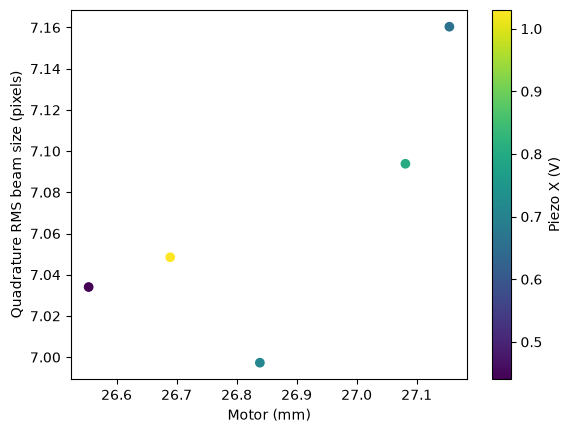

Blop best-point estimates (inspect before moving): [(0, {'piezo_x_v': 0.5, 'motor_mm': 26.83879430970149}, {'beam_size_px': (6.9973049231436155, nan)})]


In [11]:
observations = [s for rows in run_stats.values() for s in rows if s['motor_mm'] is not None]
for s in observations:
    print(f"X={s['piezo_x_v']:.3f} V, motor={s['motor_mm']:.4f} mm, "
          f"size={s['size_quadrature_px']:.2f} px, center=({s['center_x_px']:.1f},{s['center_y_px']:.1f}) px")
if observations:
    plt.scatter([s['motor_mm'] for s in observations],
                [s['size_quadrature_px'] for s in observations],
                c=[s['piezo_x_v'] for s in observations], cmap='viridis')
    plt.xlabel('Motor (mm)')
    plt.ylabel('Quadrature RMS beam size (pixels)')
    plt.colorbar(label='Piezo X (V)')
    plt.show()
print('Blop best-point estimates (inspect before moving):', agent.get_best_points())

## Future target-based centering (disabled)

Set `x0`, `y0` in **pixels**, fix the second piezo driver, and verify both axes actually control the intended beam directions before using this. Centering competes with size minimization; start a separate centering agent or use a multi-objective/constraint approach rather than silently changing the current objective. Keep disabled until tested.

In [ ]:
x0 = None  # TODO: target beam center x in camera pixels
y0 = None  # TODO: target beam center y in camera pixels

# Uncomment and adapt only after connecting and validating the second controller:
# if x0 is None or y0 is None:
#     raise ValueError('Set target coordinates in camera pixels first')
# y_now = float(piezo_y.read()[piezo_y.name]['value'])
# y_bounds_v = (y_now, y_now + 1.0)  # Check 0 <= bounds <= driver limit.
# def evaluate_center(uid, suggestions):
#     rows = run_stats[uid]
#     if len(rows) != len(suggestions):
#         raise RuntimeError('Missing centering images')
#     results = []
#     for suggestion, stats in zip(suggestions, rows):
#         height, width = stats['image_shape']
#         cx, cy = stats['center_x_px'], stats['center_y_px']
#         if (stats['peak_intensity'] < min_peak or stats['peak_intensity'] > max_peak
#                 or stats['total_intensity'] < min_total
#                 or not (edge_margin_px <= cx < width - edge_margin_px)
#                 or not (edge_margin_px <= cy < height - edge_margin_px)):
#             raise RuntimeError('Invalid beam for centering')
#         results.append({'_id': suggestion['_id'],
#                         'center_error_px': math.hypot(cx - x0, cy - y0)})
#     return results
# center_agent = Agent(sensors=[camera], dofs=[
#     RangeDOF(actuator=piezo_x, bounds=piezo_bounds_v, parameter_type='float'),
#     RangeDOF(actuator=piezo_y, bounds=y_bounds_v, parameter_type='float'),
# ], objectives=[Objective(name='center_error_px', minimize=True)],
#     evaluation_function=evaluate_center)
# RE(center_agent.optimize(iterations=5, n_points=1))  # MOTION; review bounds first.

## Disconnect (does not move stages)

Only execute after the RunEngine has finished. Navigating to the optimum is optional; inspect `agent.get_best_points()` first, then explicitly run `RE(agent.navigate_to_best())` if safe. This is **motion**, and not run as part of this notebook.

In [ ]:
# Run when done; do not run while an optimization is active.
camera.close()
motor_driver.close()
piezo_driver.close()
# piezo_y_driver.close()  # Only if the commented-out Y connection was enabled.